# ✅ Missing Value Handling: Constant Imputation (99 / -1 / 999)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer


In [2]:
# ==========================================================
# 1) Load Dataset
# ==========================================================

df = pd.read_csv('titanic_toy.csv')

print("✅ Dataset Shape:", df.shape)
print(df.head(), "\n")

print("✅ Missing Ratio:")
print(df.isnull().mean(), "\n")

✅ Dataset Shape: (891, 4)
    Age     Fare  Family  Survived
0  22.0   7.2500       1         0
1  38.0  71.2833       1         1
2  26.0   7.9250       0         1
3  35.0  53.1000       1         1
4  35.0   8.0500       0         0 

✅ Missing Ratio:
Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64 



In [3]:
# ==========================================================
# 2) Split into X and y
# ==========================================================

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=2
)

print("✅ Train shape:", X_train.shape)
print("✅ Test shape:", X_test.shape, "\n")


✅ Train shape: (712, 3)
✅ Test shape: (179, 3) 



In [4]:
# ==========================================================
# 3) Manual Constant Imputation (Pandas)
# ==========================================================
# ✅ Fix warning: always take a copy
X_train_copy = X_train.copy()

# Create constant-imputed columns
X_train_copy.loc[:, 'Age_99'] = X_train_copy['Age'].fillna(99)
X_train_copy.loc[:, 'Age_minus1'] = X_train_copy['Age'].fillna(-1)

X_train_copy.loc[:, 'Fare_999'] = X_train_copy['Fare'].fillna(999)
X_train_copy.loc[:, 'Fare_minus1'] = X_train_copy['Fare'].fillna(-1)

print("✅ Sample after constant-imputed columns:")
print(X_train_copy.sample(5), "\n")

✅ Sample after constant-imputed columns:
      Age      Fare  Family  Age_99  Age_minus1  Fare_999  Fare_minus1
306   NaN  110.8833       0    99.0        -1.0  110.8833     110.8833
659  58.0  113.2750       2    58.0        58.0  113.2750     113.2750
180   NaN   69.5500      10    99.0        -1.0   69.5500      69.5500
75   25.0    7.6500       0    25.0        25.0    7.6500       7.6500
220  16.0    8.0500       0    16.0        16.0    8.0500       8.0500 



In [5]:
# ==========================================================
# 4) Variance Comparison (Before vs After)
# ==========================================================

print("✅ Variance Comparison:\n")

print("Original Age variance:", X_train_copy['Age'].var())
print("Age variance after 99 imputation:", X_train_copy['Age_99'].var())
print("Age variance after -1 imputation:", X_train_copy['Age_minus1'].var(), "\n")

print("Original Fare variance:", X_train_copy['Fare'].var())
print("Fare variance after 999 imputation:", X_train_copy['Fare_999'].var())
print("Fare variance after -1 imputation:", X_train_copy['Fare_minus1'].var(), "\n")


✅ Variance Comparison:

Original Age variance: 204.3495133904614
Age variance after 99 imputation: 951.7275570187172
Age variance after -1 imputation: 318.0896202624484 

Original Fare variance: 2448.197913706318
Fare variance after 999 imputation: 47219.20265217623
Fare variance after -1 imputation: 2378.5676784883503 



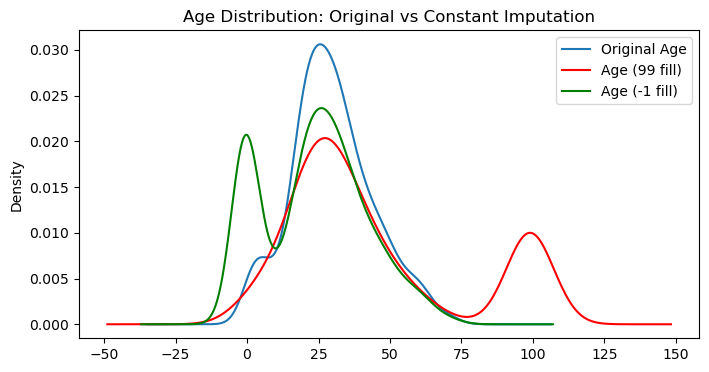

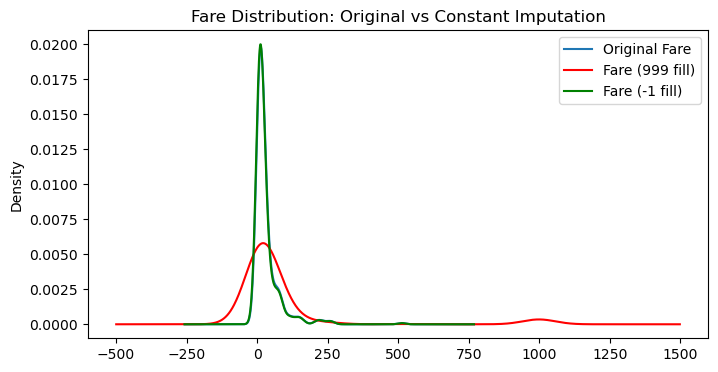

In [6]:
# ==========================================================
# 5) KDE Plot Comparison (Distribution)
# ==========================================================

# ---- Age KDE ----
plt.figure(figsize=(8,4))
X_train_copy['Age'].plot(kind='kde', label="Original Age")
X_train_copy['Age_99'].plot(kind='kde', color='red', label="Age (99 fill)")
X_train_copy['Age_minus1'].plot(kind='kde', color='green', label="Age (-1 fill)")
plt.title("Age Distribution: Original vs Constant Imputation")
plt.legend()
plt.show()

# ---- Fare KDE ----
plt.figure(figsize=(8,4))
X_train_copy['Fare'].plot(kind='kde', label="Original Fare")
X_train_copy['Fare_999'].plot(kind='kde', color='red', label="Fare (999 fill)")
X_train_copy['Fare_minus1'].plot(kind='kde', color='green', label="Fare (-1 fill)")
plt.title("Fare Distribution: Original vs Constant Imputation")
plt.legend()
plt.show()

In [7]:

# ==========================================================
# 6) Covariance & Correlation Check (Optional)
# ==========================================================

print("✅ Covariance Matrix:")
print(X_train_copy.cov(), "\n")

print("✅ Correlation Matrix:")
print(X_train_copy.corr(), "\n")


✅ Covariance Matrix:
                    Age         Fare     Family      Age_99  Age_minus1  \
Age          204.349513    70.719262  -6.498901  204.349513  204.349513   
Fare          70.719262  2448.197914  17.258917 -101.671097  125.558364   
Family        -6.498901    17.258917   2.735252   -7.387287   -4.149246   
Age_99       204.349513  -101.671097  -7.387287  951.727557 -189.535540   
Age_minus1   204.349513   125.558364  -4.149246 -189.535540  318.089620   
Fare_999     162.793430  2448.197914  11.528625 -159.931663  257.379887   
Fare_minus1   63.321188  2448.197914  16.553989  -94.317400  114.394141   

                 Fare_999  Fare_minus1  
Age            162.793430    63.321188  
Fare          2448.197914  2448.197914  
Family          11.528625    16.553989  
Age_99        -159.931663   -94.317400  
Age_minus1     257.379887   114.394141  
Fare_999     47219.202652   762.474982  
Fare_minus1    762.474982  2378.567678   

✅ Correlation Matrix:
                  Age     

In [8]:
# ==========================================================
# ✅ 7) Using Sklearn (Best Practice)
# ==========================================================

# Fresh split again (clean)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=2
)

# Constant imputers
imputer_age = SimpleImputer(strategy='constant', fill_value=99)
imputer_fare = SimpleImputer(strategy='constant', fill_value=999)

# ColumnTransformer (Age -> 99, Fare -> 999)
trf = ColumnTransformer(
    transformers=[
        ('imputer_age', imputer_age, ['Age']),
        ('imputer_fare', imputer_fare, ['Fare'])
    ],
    remainder='passthrough'
)

# Fit only on train
trf.fit(X_train)

print("✅ Age fill value used:", trf.named_transformers_['imputer_age'].statistics_)
print("✅ Fare fill value used:", trf.named_transformers_['imputer_fare'].statistics_)

# Transform train + test
X_train_trf = trf.transform(X_train)
X_test_trf = trf.transform(X_test)

print("\n✅ Transformed Train Data (first 5 rows):")
print(X_train_trf[:5])

✅ Age fill value used: [99.]
✅ Fare fill value used: [999.]

✅ Transformed Train Data (first 5 rows):
[[40.     27.7208  0.    ]
 [ 4.     16.7     2.    ]
 [47.      9.      0.    ]
 [ 9.     31.3875  6.    ]
 [20.      9.8458  0.    ]]
